In [1]:

# OASIS INFOBYTE
# Project: Car Price Prediction

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

print("Car Price Prediction Project Started!")
print("All libraries imported successfully!")


Car Price Prediction Project Started!
All libraries imported successfully!


In [2]:

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset uploaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Saving car details v4.csv to car details v4 (1).csv
Saving car data.csv to car data (1).csv
Saving CAR DETAILS FROM CAR DEKHO.csv to CAR DETAILS FROM CAR DEKHO (1).csv
Saving Car details v3.csv to Car details v3 (1).csv
Dataset uploaded successfully!
Dataset shape: (2059, 20)


,Make,Model,Price,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,Seller Type,Engine,Max Power,Max Torque,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
0,Honda,Amaze 1.2 VX i-VTEC,505000,2017,87150,Petrol,Manual,Pune,Grey,First,Corporate,1198 cc,87 bhp @ 6000 rpm,109 Nm @ 4500 rpm,FWD,3990.0,1680.0,1505.0,5.0,35.0
1,Maruti Suzuki,Swift DZire VDI,450000,2014,75000,Diesel,Manual,Ludhiana,White,Second,Individual,1248 cc,74 bhp @ 4000 rpm,190 Nm @ 2000 rpm,FWD,3995.0,1695.0,1555.0,5.0,42.0
2,Hyundai,i10 Magna 1.2 Kappa2,220000,2011,67000,Petrol,Manual,Lucknow,Maroon,First,Individual,1197 cc,79 bhp @ 6000 rpm,112.7619 Nm @ 4000 rpm,FWD,3585.0,1595.0,1550.0,5.0,35.0
3,Toyota,Glanza G,799000,2019,37500,Petrol,Manual,Mangalore,Red,First,Individual,1197 cc,82 bhp @ 6000 rpm,113 Nm @ 4200 rpm,FWD,3995.0,1745.0,1510.0,5.0,37.0
4,Toyota,Innova 2.4 VX 7 STR [2016-2020],1950000,2018,69000,Diesel,Manual,Mumbai,Grey,First,Individual,2393 cc,148 bhp @ 3400 rpm,343 Nm @ 1400 rpm,RWD,4735.0,1830.0,1795.0,7.0,55.0


In [3]:

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe(include="all"))


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2059 entries, 0 to 2058
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Make                2059 non-null   object 
 1   Model               2059 non-null   object 
 2   Price               2059 non-null   int64  
 3   Year                2059 non-null   int64  
 4   Kilometer           2059 non-null   int64  
 5   Fuel Type           2059 non-null   object 
 6   Transmission        2059 non-null   object 
 7   Location            2059 non-null   object 
 8   Color               2059 non-null   object 
 9   Owner               2059 non-null   object 
 10  Seller Type         2059 non-null   object 
 11  Engine              1979 non-null   object 
 12  Max Power           1979 non-null   object 
 13  Max Torque          1979 non-null   object 
 14  Drivetrain          1923 non-null   object 
 15  Length              1995 non-null 

,Make,Model,Price,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,Seller Type,Engine,Max Power,Max Torque,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
count,2059,2059,2.059000e+03,2059.000000,2.059000e+03,2059,2059,2059,2059,2059,2059,1979,1979,1979,1923,1995.000000,1995.000000,1995.000000,1995.000000,1946.000000
unique,33,1050,NaN,NaN,NaN,9,2,77,17,6,3,108,335,290,3,NaN,NaN,NaN,NaN,NaN
top,Maruti Suzuki,X1 sDrive20d xLine,NaN,NaN,NaN,Diesel,Manual,Mumbai,White,First,Individual,1197 cc,89 bhp @ 4000 rpm,200 Nm @ 1750 rpm,FWD,NaN,NaN,NaN,NaN,NaN
freq,440,15,NaN,NaN,NaN,1049,1133,342,802,1619,1997,231,90,90,1330,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,1.702992e+06,2016.425449,5.422471e+04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4280.860652,1767.991980,1591.735338,5.306266,52.002210
std,NaN,NaN,2.419881e+06,3.363564,5.736172e+04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,442.458507,135.265825,136.073956,0.822170,15.110198
min,NaN,NaN,4.900000e+04,1988.000000,0.000000e+00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3099.000000,1475.000000,1165.000000,2.000000,15.000000
25%,NaN,NaN,4.849990e+05,2014.000000,2.900000e+04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3985.000000,1695.000000,1485.000000,5.000000,41.250000
50%,NaN,NaN,8.250000e+05,2017.000000,5.000000e+04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4370.000000,1770.000000,1545.000000,5.000000,50.000000
75%,NaN,NaN,1.925000e+06,2019.000000,7.200000e+04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4629.000000,1831.500000,1675.000000,5.000000,60.000000


In [4]:

# OASIS INFOBYTE
# Stage 2A: Inspect vehicle specifications

print("Engine values:")
print(df["Engine"].dropna().unique()[:15])

print("\nMax Power values:")
print(df["Max Power"].dropna().unique()[:15])

print("\nMax Torque values:")
print(df["Max Torque"].dropna().unique()[:20])

print("\nDrivetrain values:")
print(df["Drivetrain"].value_counts(dropna=False))

print("\nOwner values:")
print(df["Owner"].value_counts(dropna=False))


Engine values:
['1198 cc' '1248 cc' '1197 cc' '2393 cc' '1373 cc' '1991 cc' '1995 cc'
 '1798 cc' '1461 cc' '999 cc' '1462 cc' '1956 cc' '998 cc' '796 cc'
 '1591 cc']

Max Power values:
['87 bhp @ 6000 rpm' '74 bhp @ 4000 rpm' '79 bhp @ 6000 rpm'
 '82 bhp @ 6000 rpm' '148 bhp @ 3400 rpm' '91 bhp @ 6000 rpm'
 '181 bhp @ 5500 rpm' '188 bhp @ 4000 rpm' '177 bhp @ 5100 rpm'
 '84 bhp @ 3750 rpm' '67 bhp @ 5500 rpm' '103 bhp @ 6000 rpm'
 '138 bhp @ 3750 rpm' '103 bhp @ 5000 rpm' '67 bhp @ 6000 rpm']

Max Torque values:
['109 Nm @ 4500 rpm' '190 Nm @ 2000 rpm' '112.7619 Nm @ 4000 rpm'
 '113 Nm @ 4200 rpm' '343 Nm @ 1400 rpm' '130 Nm @ 4000 rpm'
 '300 Nm @ 1200 rpm' '400 Nm @ 1750 rpm' '250 Nm @ 1250 rpm'
 '200 Nm @ 1900 rpm' '115 Nm @ 4000 rpm' '91 Nm @ 4250 rpm'
 '138 Nm @ 4400 rpm' '350 Nm @ 1750 rpm' '175 Nm @ 1500 rpm'
 '90 Nm @ 3500 rpm' '69 Nm @ 3500 rpm' '154 Nm @ 4850 rpm'
 '153 Nm @ 3800 rpm' '99 Nm @ 4500 rpm']

Drivetrain values:
Drivetrain
FWD    1330
RWD     321
AWD     272
NaN   

In [5]:

# OASIS INFOBYTE
# Project: Car Price Prediction
# Stage 2B: Feature Engineering

import pandas as pd
import numpy as np

# Work on a copy of the original dataset
df = df.copy()

# Extract numerical values from vehicle specifications
df["Engine_CC"] = pd.to_numeric(
    df["Engine"].str.extract(r"([\d.]+)")[0],
    errors="coerce"
)

df["Max_Power_BHP"] = pd.to_numeric(
    df["Max Power"].str.extract(r"([\d.]+)")[0],
    errors="coerce"
)

df["Max_Torque_Value"] = pd.to_numeric(
    df["Max Torque"].str.extract(r"([\d.]+)")[0],
    errors="coerce"
)

# Calculate car age relative to the latest year in this dataset
reference_year = int(df["Year"].max())
df["Car_Age"] = reference_year - df["Year"]

# Display newly created features
new_features = [
    "Engine_CC",
    "Max_Power_BHP",
    "Max_Torque_Value",
    "Car_Age"
]

print("Reference year:", reference_year)
print("\nNew Feature Preview:")
display(df[new_features].head(10))

print("\nMissing values in new features:")
print(df[new_features].isnull().sum())

print("\nUpdated Dataset Shape:", df.shape)


Reference year: 2022

New Feature Preview:


,Engine_CC,Max_Power_BHP,Max_Torque_Value,Car_Age
0,1198.0,87.0,109.0000,5
1,1248.0,74.0,190.0000,8
2,1197.0,79.0,112.7619,11
3,1197.0,82.0,113.0000,3
4,2393.0,148.0,343.0000,4
5,1373.0,91.0,130.0000,5
6,1991.0,181.0,300.0000,7
7,1995.0,188.0,400.0000,5
8,1798.0,177.0,250.0000,5
9,1461.0,84.0,200.0000,7



Missing values in new features:
Engine_CC           80
Max_Power_BHP       80
Max_Torque_Value    80
Car_Age              0
dtype: int64

Updated Dataset Shape: (2059, 24)


In [6]:

# Stage 2C: Feature validation

print("Feature Statistics:")
display(df[
    ["Engine_CC", "Max_Power_BHP",
     "Max_Torque_Value", "Car_Age"]
].describe())

print("\nInvalid or unusual values:")

for col in ["Engine_CC", "Max_Power_BHP", "Max_Torque_Value"]:
    print(f"\n{col}")
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())

print("\nCar age distribution:")
print(df["Car_Age"].value_counts().sort_index())


Feature Statistics:


,Engine_CC,Max_Power_BHP,Max_Torque_Value,Car_Age
count,1979.000000,1979.000000,1979.000000,2059.000000
mean,1692.575543,129.611774,245.851019,5.574551
std,643.736294,65.073797,140.465731,3.363564
min,624.000000,35.000000,48.000000,0.000000
25%,1197.000000,83.000000,115.000000,3.000000
50%,1498.000000,116.000000,200.000000,5.000000
75%,1995.000000,171.000000,350.000000,8.000000
max,6592.000000,660.000000,780.000000,34.000000



Invalid or unusual values:

Engine_CC
Minimum: 624.0
Maximum: 6592.0

Max_Power_BHP
Minimum: 35.0
Maximum: 660.0

Max_Torque_Value
Minimum: 48.0
Maximum: 780.0

Car age distribution:
Car_Age
0      81
1     156
2     132
3     218
4     268
5     262
6     187
7     178
8     192
9     128
10     92
11     79
12     27
13     33
14     13
15      6
16      2
18      1
20      1
22      1
26      1
34      1
Name: count, dtype: int64


In [7]:

# OASIS INFOBYTE
# Stage 3A: Numerical Data Analysis

print("Price Statistics:")
display(df["Price"].describe())

print("\nPrice Skewness:", round(df["Price"].skew(), 2))

print("\nKilometer Statistics:")
display(df["Kilometer"].describe())

print("\nTop 10 Highest Mileage Records:")
display(
    df.nlargest(10, "Kilometer")[
        ["Make", "Model", "Year", "Kilometer", "Price"]
    ]
)

print("\nPrice Percentiles:")
print(df["Price"].quantile([0.01, 0.25, 0.50, 0.75, 0.95, 0.99]))


Price Statistics:


,Price
count,2.059000e+03
mean,1.702992e+06
std,2.419881e+06
min,4.900000e+04
25%,4.849990e+05
50%,8.250000e+05
75%,1.925000e+06
max,3.500000e+07



Price Skewness: 4.97

Kilometer Statistics:


,Kilometer
count,2.059000e+03
mean,5.422471e+04
std,5.736172e+04
min,0.000000e+00
25%,2.900000e+04
50%,5.000000e+04
75%,7.200000e+04
max,2.000000e+06



Top 10 Highest Mileage Records:


,Make,Model,Year,Kilometer,Price
1125,Renault,Duster 110 PS RXZ 4X2 MT Diesel,2016,2000000,450000
1866,Hyundai,Verna 1.6 CRDI SX,2018,925000,925000
1515,Hyundai,Creta SX 1.6 AT CRDi,2018,440000,1240000
1992,Toyota,Innova 2.0 G1 BS-IV,2010,261236,555000
733,Audi,A6 3.0 TDI quattro Premium,2012,240000,1650000
1628,Toyota,Innova 2.5 V 7 STR,2012,222000,960000
1991,Toyota,Fortuner 2.8 4x4 AT [2016-2020],2017,219000,2750000
181,Toyota,Fortuner 3.0 4x4 MT,2014,211000,1675000
134,BMW,5-Series 520d Sedan,2013,195000,1490000
388,Tata,Grande GX,2011,192326,199000



Price Percentiles:
0.01      160000.0
0.25      484999.0
0.50      825000.0
0.75     1925000.0
0.95     5900000.0
0.99    10842000.0
Name: Price, dtype: float64


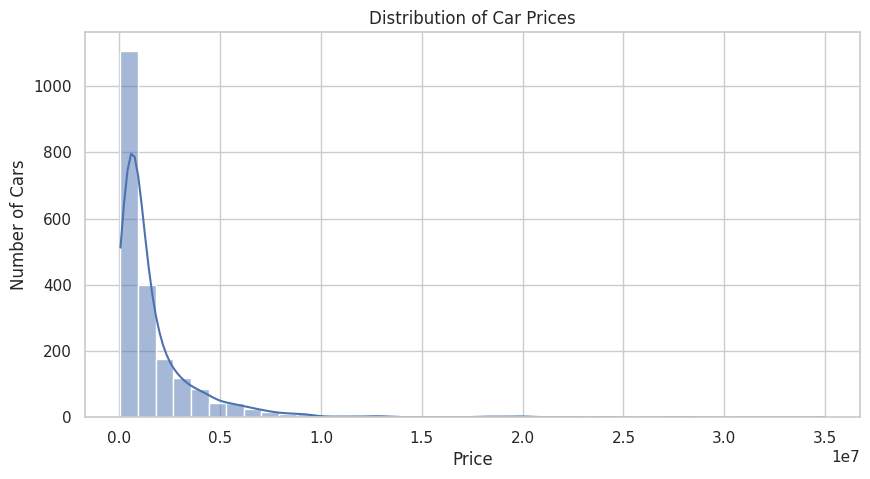

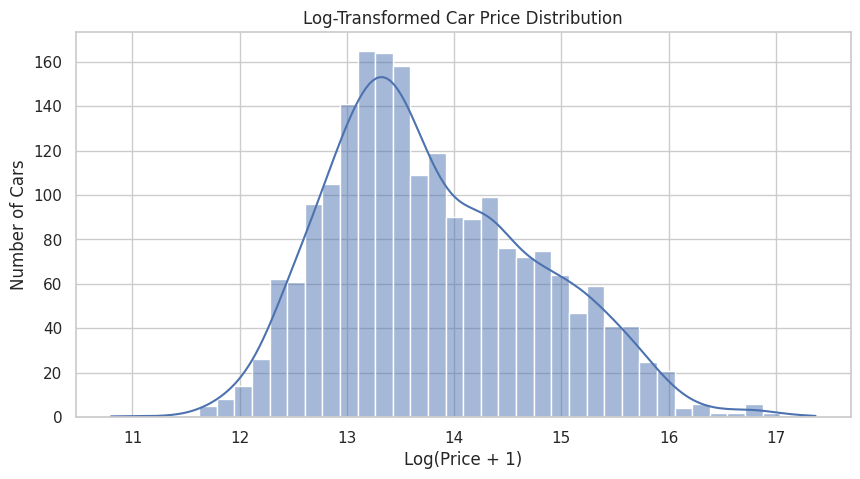

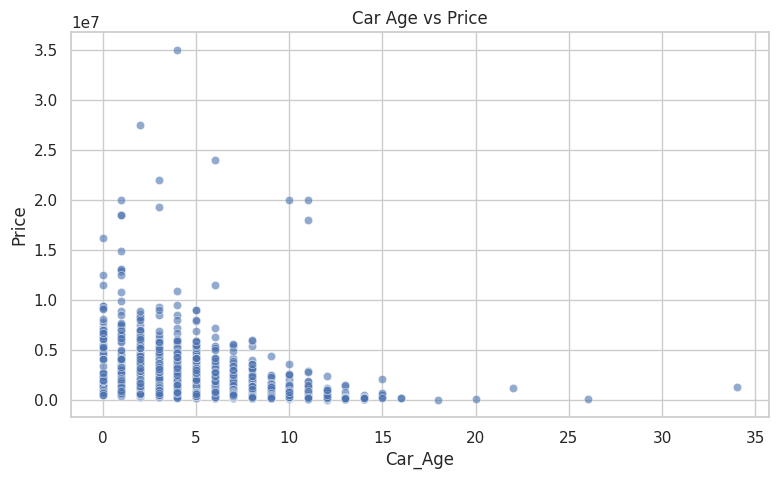

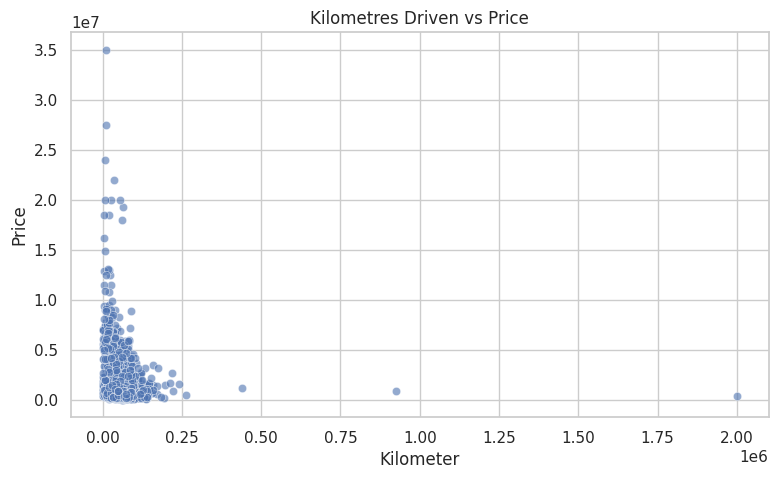

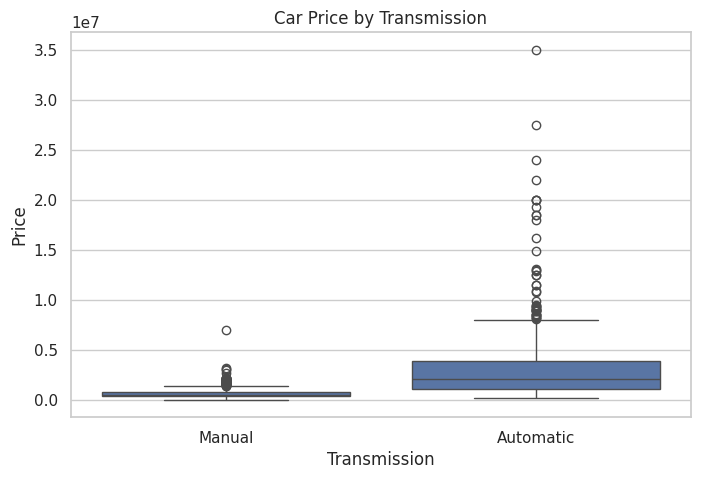

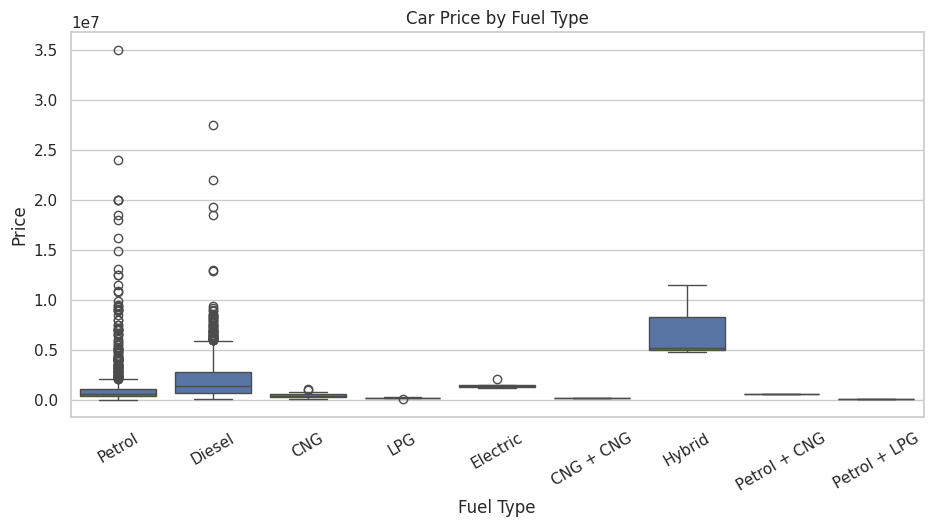

In [8]:

# Stage 3B: Exploratory Data Visualizations

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Distribution of car prices
plt.figure(figsize=(10, 5))
sns.histplot(df["Price"], bins=40, kde=True)
plt.title("Distribution of Car Prices")
plt.xlabel("Price")
plt.ylabel("Number of Cars")
plt.show()

# 2. Log-transformed price distribution
plt.figure(figsize=(10, 5))
sns.histplot(np.log1p(df["Price"]), bins=40, kde=True)
plt.title("Log-Transformed Car Price Distribution")
plt.xlabel("Log(Price + 1)")
plt.ylabel("Number of Cars")
plt.show()

# 3. Car price versus car age
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x="Car_Age", y="Price", alpha=0.6)
plt.title("Car Age vs Price")
plt.show()

# 4. Car price versus kilometres driven
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x="Kilometer", y="Price", alpha=0.6)
plt.title("Kilometres Driven vs Price")
plt.show()

# 5. Price by transmission
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Transmission", y="Price")
plt.title("Car Price by Transmission")
plt.show()

# 6. Price by fuel type
plt.figure(figsize=(11, 5))
sns.boxplot(data=df, x="Fuel Type", y="Price")
plt.title("Car Price by Fuel Type")
plt.xticks(rotation=30)
plt.show()


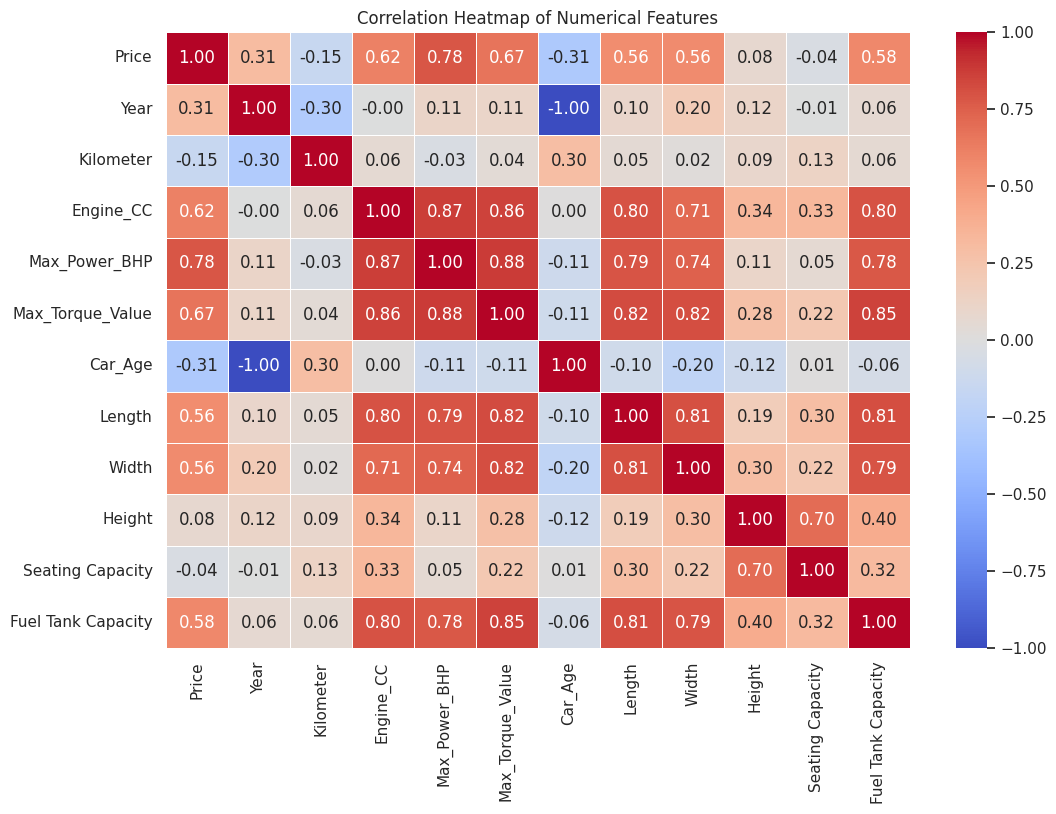

Correlation with Price:


,Correlation with Price
Price,1.000000
Max_Power_BHP,0.781419
Max_Torque_Value,0.671290
Engine_CC,0.615328
Fuel Tank Capacity,0.584631
Width,0.563996
Length,0.556741
Year,0.311400
Height,0.075080
Seating Capacity,-0.038524


In [9]:

# Stage 3C: Correlation Heatmap

numeric_columns = [
    "Price",
    "Year",
    "Kilometer",
    "Engine_CC",
    "Max_Power_BHP",
    "Max_Torque_Value",
    "Car_Age",
    "Length",
    "Width",
    "Height",
    "Seating Capacity",
    "Fuel Tank Capacity"
]

correlation = df[numeric_columns].corr(numeric_only=True)

plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

print("Correlation with Price:")
display(
    correlation["Price"]
    .sort_values(ascending=False)
    .to_frame("Correlation with Price")
)


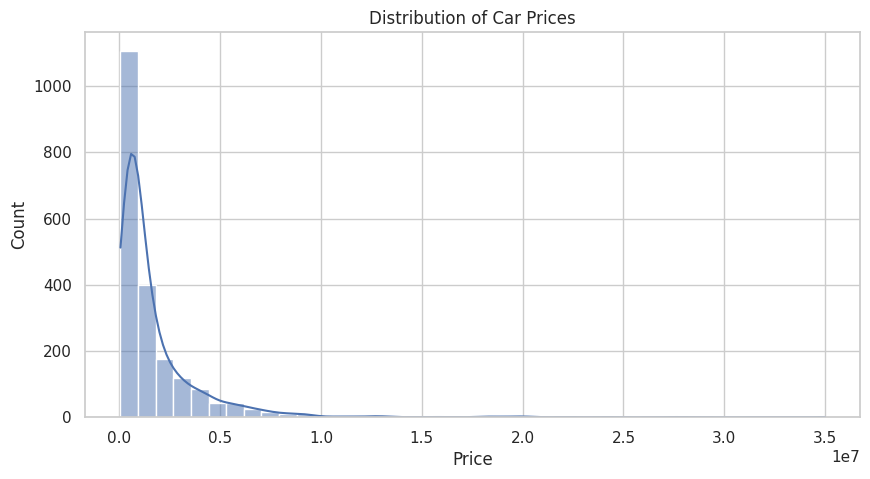

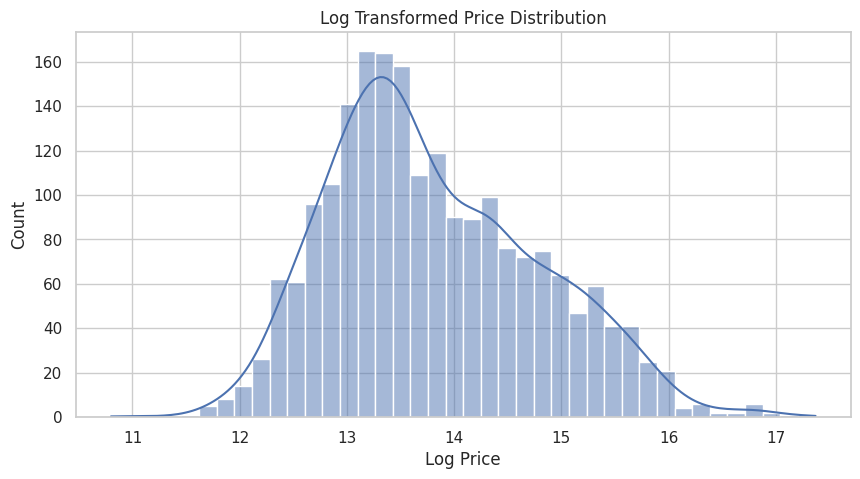

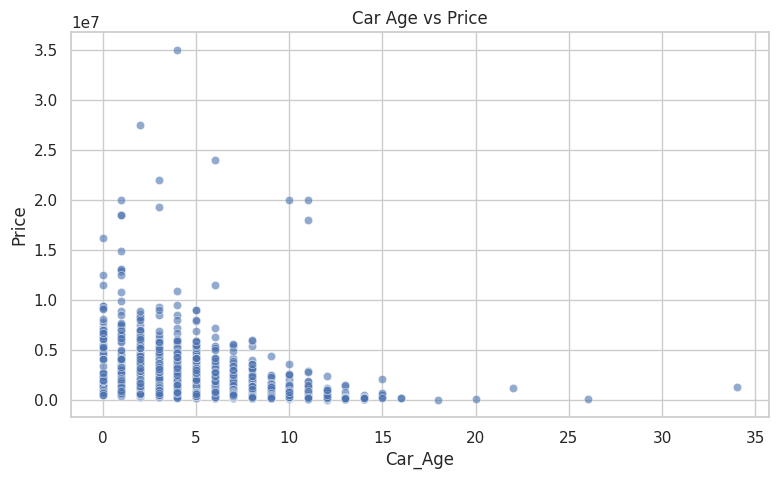

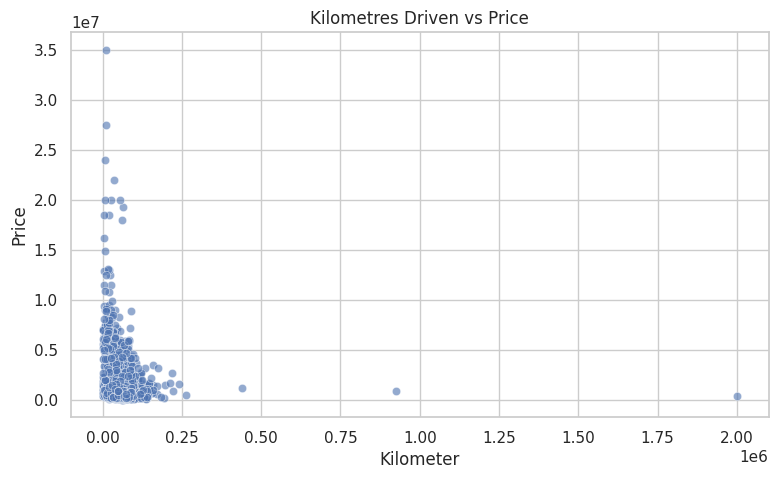

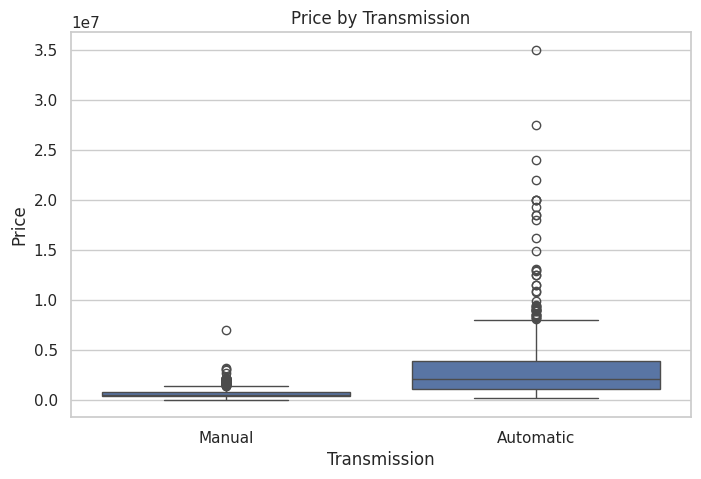

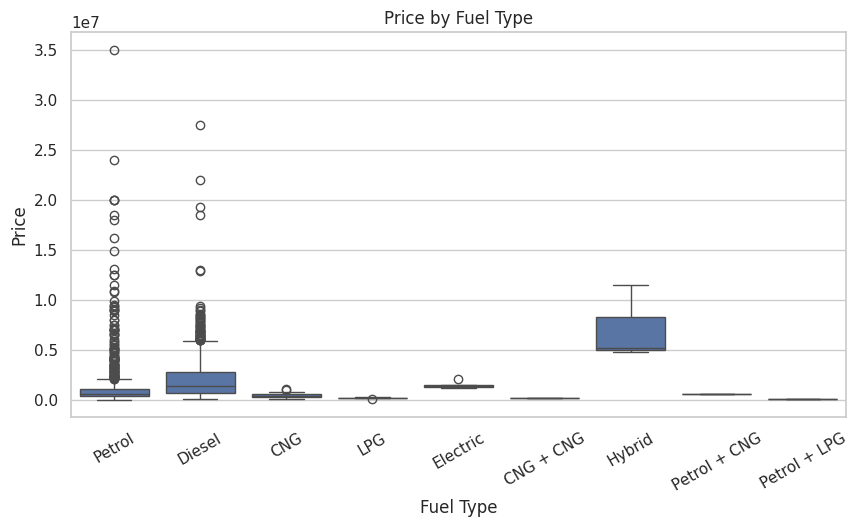

Price skewness: 4.97

Price summary:


,Price
count,2.059000e+03
mean,1.702992e+06
std,2.419881e+06
min,4.900000e+04
25%,4.849990e+05
50%,8.250000e+05
75%,1.925000e+06
max,3.500000e+07



Highest 10 kilometre readings:


,Make,Model,Year,Kilometer,Price
1125,Renault,Duster 110 PS RXZ 4X2 MT Diesel,2016,2000000,450000
1866,Hyundai,Verna 1.6 CRDI SX,2018,925000,925000
1515,Hyundai,Creta SX 1.6 AT CRDi,2018,440000,1240000
1992,Toyota,Innova 2.0 G1 BS-IV,2010,261236,555000
733,Audi,A6 3.0 TDI quattro Premium,2012,240000,1650000
1628,Toyota,Innova 2.5 V 7 STR,2012,222000,960000
1991,Toyota,Fortuner 2.8 4x4 AT [2016-2020],2017,219000,2750000
181,Toyota,Fortuner 3.0 4x4 MT,2014,211000,1675000
134,BMW,5-Series 520d Sedan,2013,195000,1490000
388,Tata,Grande GX,2011,192326,199000


In [10]:

# OASIS INFOBYTE
# Car Price Prediction
# Stage 3: Exploratory Data Analysis

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid")

# 1. Price distribution
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="Price", bins=40, kde=True)
plt.title("Distribution of Car Prices")
plt.xlabel("Price")
plt.show()

# 2. Log price distribution
plt.figure(figsize=(10, 5))
sns.histplot(np.log1p(df["Price"]), bins=40, kde=True)
plt.title("Log Transformed Price Distribution")
plt.xlabel("Log Price")
plt.show()

# 3. Price vs car age
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x="Car_Age", y="Price", alpha=0.6)
plt.title("Car Age vs Price")
plt.show()

# 4. Price vs kilometres
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x="Kilometer", y="Price", alpha=0.6)
plt.title("Kilometres Driven vs Price")
plt.show()

# 5. Price by transmission
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Transmission", y="Price")
plt.title("Price by Transmission")
plt.show()

# 6. Price by fuel type
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="Fuel Type", y="Price")
plt.title("Price by Fuel Type")
plt.xticks(rotation=30)
plt.show()

print("Price skewness:", round(df["Price"].skew(), 2))
print("\nPrice summary:")
display(df["Price"].describe())

print("\nHighest 10 kilometre readings:")
display(
    df.nlargest(10, "Kilometer")[
        ["Make", "Model", "Year", "Kilometer", "Price"]
    ]
)


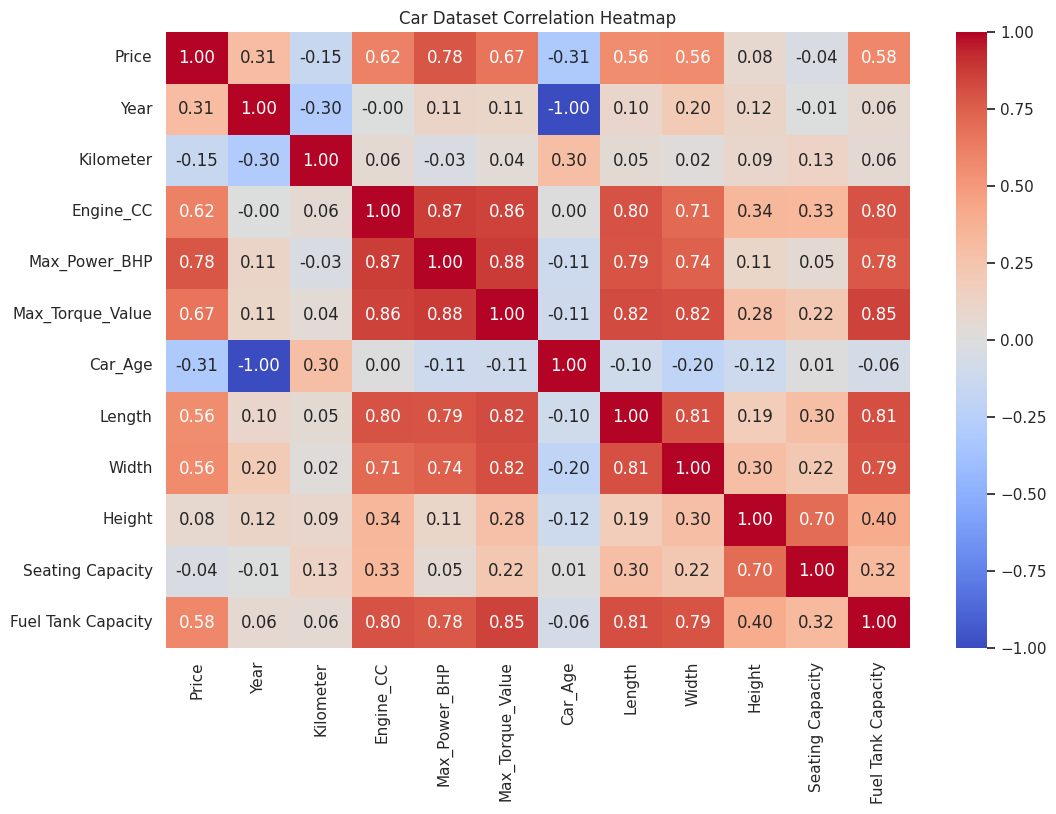

Features most correlated with Price:


,Price
Price,1.000000
Max_Power_BHP,0.781419
Max_Torque_Value,0.671290
Engine_CC,0.615328
Fuel Tank Capacity,0.584631
Width,0.563996
Length,0.556741
Year,0.311400
Height,0.075080
Seating Capacity,-0.038524


In [11]:

numeric_columns = [
    "Price", "Year", "Kilometer",
    "Engine_CC", "Max_Power_BHP",
    "Max_Torque_Value", "Car_Age",
    "Length", "Width", "Height",
    "Seating Capacity", "Fuel Tank Capacity"
]

correlation = df[numeric_columns].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Car Dataset Correlation Heatmap")
plt.show()

print("Features most correlated with Price:")
display(
    correlation["Price"]
    .sort_values(ascending=False)
    .to_frame()
)


In [12]:

# OASIS INFOBYTE
# Stage 4: Data Cleaning and Preprocessing

import pandas as pd
import numpy as np

# Create a fresh working copy
model_df = df.copy()

# Remove duplicate rows
model_df = model_df.drop_duplicates()

# Remove raw text specification columns
# Their numerical information has already been extracted
model_df = model_df.drop(
    columns=["Engine", "Max Power", "Max Torque"],
    errors="ignore"
)

# Remove records with missing target values
model_df = model_df.dropna(subset=["Price"])

# Remove rows with impossible target values
model_df = model_df[model_df["Price"] > 0]

# Separate target and features
X = model_df.drop(columns=["Price"])
y = model_df["Price"]

print("Dataset after initial cleaning")
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nMissing values in features:")
display(X.isnull().sum().sort_values(ascending=False))

print("\nTarget statistics:")
display(y.describe())


Dataset after initial cleaning
Feature shape: (2059, 20)
Target shape: (2059,)

Missing values in features:


,0
Drivetrain,136
Fuel Tank Capacity,113
Max_Power_BHP,80
Max_Torque_Value,80
Engine_CC,80
Length,64
Height,64
Seating Capacity,64
Width,64
Year,0



Target statistics:


,Price
count,2.059000e+03
mean,1.702992e+06
std,2.419881e+06
min,4.900000e+04
25%,4.849990e+05
50%,8.250000e+05
75%,1.925000e+06
max,3.500000e+07


In [13]:

# Stage 4B: Train-test split and preprocessing

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify numerical and categorical features
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Split before fitting preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])
print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)


Training records: 1647
Testing records: 412
Numerical features: ['Year', 'Kilometer', 'Length', 'Width', 'Height', 'Seating Capacity', 'Fuel Tank Capacity', 'Engine_CC', 'Max_Power_BHP', 'Max_Torque_Value', 'Car_Age']
Categorical features: ['Make', 'Model', 'Fuel Type', 'Transmission', 'Location', 'Color', 'Owner', 'Seller Type', 'Drivetrain']


In [15]:

# OASIS INFOBYTE
# Stage 5A: Import Machine Learning Models

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import pandas as pd
import numpy as np

print("Machine learning libraries imported successfully!")



Machine learning libraries imported successfully!


In [16]:

# OASIS INFOBYTE
# Stage 5B: Model Training

models = {
    "Ridge Regression": Ridge(alpha=10),
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        max_depth=None,
        min_samples_split=4,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=300,
        min_samples_split=4,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}
results = []

for name, model in models.items():

    print(f"\nTraining {name}...")

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    trained_models[name] = pipeline

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

    print(f"{name} training completed!")
    print(f"MAE: {mae:,.2f}")
    print(f"RMSE: {rmse:,.2f}")
    print(f"R2 Score: {r2:.4f}")

print("\nAll models trained successfully!")



Training Ridge Regression...
Ridge Regression training completed!
MAE: 630,324.47
RMSE: 1,342,240.28
R2 Score: 0.7421

Training Random Forest...
Random Forest training completed!
MAE: 305,850.30
RMSE: 1,159,218.65
R2 Score: 0.8077

Training Extra Trees...
Extra Trees training completed!
MAE: 276,777.98
RMSE: 1,058,051.44
R2 Score: 0.8398

All models trained successfully!


In [17]:

# OASIS INFOBYTE
# Stage 5C: Model Evaluation and Comparison

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

print("MODEL PERFORMANCE COMPARISON")
display(results_df.round(3))

best_model_name = results_df.iloc[0]["Model"]

print("\nBest model based on lowest RMSE:")
print(best_model_name)


MODEL PERFORMANCE COMPARISON


,Model,MAE,RMSE,R2 Score
0,Extra Trees,276777.984,1058051.445,0.840
1,Random Forest,305850.302,1159218.649,0.808
2,Ridge Regression,630324.465,1342240.276,0.742



Best model based on lowest RMSE:
Extra Trees


In [18]:

# OASIS INFOBYTE
# Stage 6A: Predictions using Extra Trees

best_model = trained_models[best_model_name]

y_pred = best_model.predict(X_test)

prediction_results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

prediction_results["Error"] = (
    prediction_results["Actual Price"] -
    prediction_results["Predicted Price"]
)

prediction_results["Absolute Error"] = (
    prediction_results["Error"].abs()
)

print("Best Model:", best_model_name)
print("\nSample Predictions:")
display(prediction_results.head(15).round(2))

print("\nAverage Absolute Error:")
print(round(prediction_results["Absolute Error"].mean(), 2))


Best Model: Extra Trees

Sample Predictions:


,Actual Price,Predicted Price,Error,Absolute Error
0,4800000,5012019.98,-212019.98,212019.98
1,825000,788914.78,36085.22,36085.22
2,695000,567875.26,127124.74,127124.74
3,950000,1081352.75,-131352.75,131352.75
4,819999,795837.46,24161.54,24161.54
5,310000,398396.85,-88396.85,88396.85
6,1000000,895283.33,104716.67,104716.67
7,1998999,2375245.50,-376246.50,376246.50
8,850000,1470161.88,-620161.88,620161.88
9,3950000,4763738.88,-813738.88,813738.88



Average Absolute Error:
276777.98


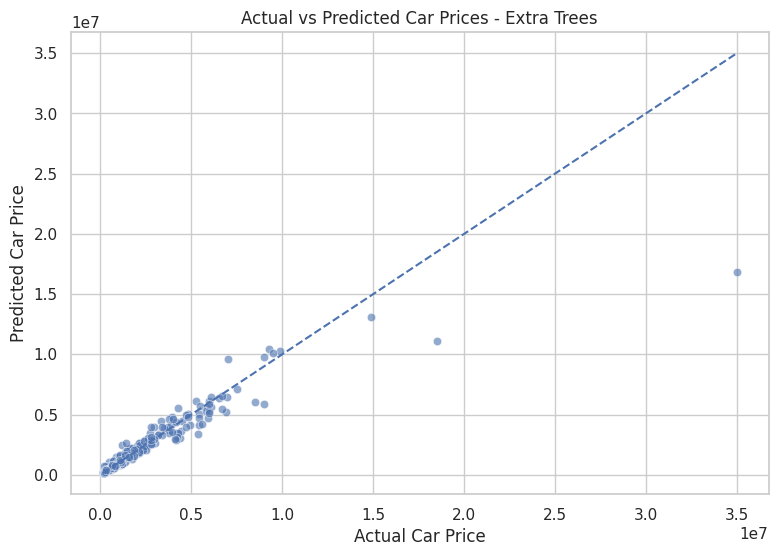

In [19]:

# Stage 6B: Actual vs Predicted Price Plot

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred,
    alpha=0.6
)

# Perfect prediction reference line
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual Car Price")
plt.ylabel("Predicted Car Price")
plt.title("Actual vs Predicted Car Prices - Extra Trees")
plt.show()


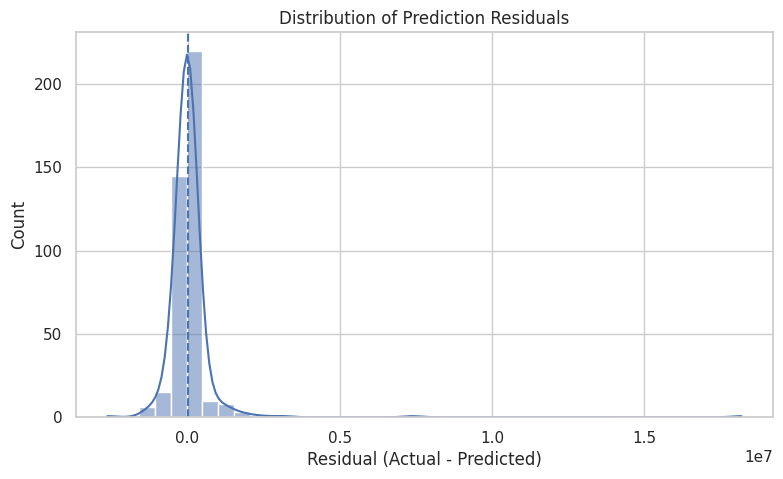

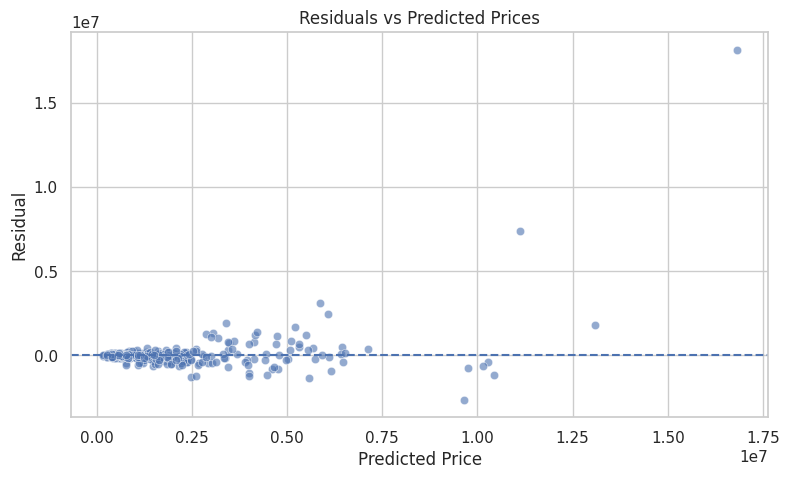

Mean Residual: 64411.29
Maximum Absolute Error: 18187666.67
Median Absolute Error: 81907.29


In [20]:

# Stage 6C: Residual Analysis

residuals = y_test.values - y_pred

# Residual distribution
plt.figure(figsize=(9, 5))
sns.histplot(residuals, bins=40, kde=True)
plt.axvline(0, linestyle="--")
plt.title("Distribution of Prediction Residuals")
plt.xlabel("Residual (Actual - Predicted)")
plt.show()

# Residuals against predicted prices
plt.figure(figsize=(9, 5))
sns.scatterplot(x=y_pred, y=residuals, alpha=0.6)
plt.axhline(0, linestyle="--")
plt.title("Residuals vs Predicted Prices")
plt.xlabel("Predicted Price")
plt.ylabel("Residual")
plt.show()

print("Mean Residual:", round(residuals.mean(), 2))
print("Maximum Absolute Error:", round(np.abs(residuals).max(), 2))
print("Median Absolute Error:", round(np.median(np.abs(residuals)), 2))


In [21]:

# Stage 6D: Training vs Testing Performance

train_predictions = best_model.predict(X_train)

train_r2 = r2_score(y_train, train_predictions)
test_r2 = r2_score(y_test, y_pred)

train_rmse = np.sqrt(mean_squared_error(y_train, train_predictions))
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))

comparison = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "R2 Score": [train_r2, test_r2],
    "RMSE": [train_rmse, test_rmse]
})

display(comparison.round(3))


,Dataset,R2 Score,RMSE
0,Training,0.983,307472.616
1,Testing,0.840,1058051.445


In [22]:

# OASIS INFOBYTE
# Stage 7A: Hyperparameter Tuning

from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.pipeline import Pipeline
import numpy as np

# Create a new Extra Trees pipeline
tuning_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", ExtraTreesRegressor(
        n_estimators=250,
        random_state=42,
        n_jobs=1
    ))
])

# Parameters to investigate
param_grid = {
    "model__max_depth": [10, 15, 20, 25, None],
    "model__min_samples_split": [4, 6, 8, 10, 12],
    "model__min_samples_leaf": [2, 3, 5, 8, 10],
    "model__max_features": [0.5, 0.7, 0.9, 1.0]
}

# Five-fold cross-validation
random_search = RandomizedSearchCV(
    estimator=tuning_pipeline,
    param_distributions=param_grid,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("Starting hyperparameter tuning...")

random_search.fit(X_train, y_train)

print("\nBest Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation RMSE:")
print(round(-random_search.best_score_, 2))


Starting hyperparameter tuning...
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Best Parameters:
{'model__min_samples_split': 4, 'model__min_samples_leaf': 2, 'model__max_features': 0.9, 'model__max_depth': None}

Best Cross-Validation RMSE:
989961.98


In [24]:

# Stage 7B: Evaluate Tuned Model

best_tuned_model = random_search.best_estimator_

# Predictions
tuned_train_pred = best_tuned_model.predict(X_train)
tuned_test_pred = best_tuned_model.predict(X_test)

# Evaluation
tuned_results = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "MAE": [
        mean_absolute_error(y_train, tuned_train_pred),
        mean_absolute_error(y_test, tuned_test_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_train, tuned_train_pred)),
        np.sqrt(mean_squared_error(y_test, tuned_test_pred))
    ],
    "R2 Score": [
        r2_score(y_train, tuned_train_pred),
        r2_score(y_test, tuned_test_pred)
    ]
})

print("TUNED EXTRA TREES PERFORMANCE")
display(tuned_results.round(3))


TUNED EXTRA TREES PERFORMANCE


,Dataset,MAE,RMSE,R2 Score
0,Training,84331.229,325134.219,0.981
1,Testing,280817.909,1118083.215,0.821


FEATURE IMPORTANCE RANKING


,Feature,Importance,Std
17,Max_Power_BHP,0.3139,0.0148
10,Drivetrain,0.0911,0.0449
5,Transmission,0.0785,0.0138
18,Max_Torque_Value,0.0765,0.0129
19,Car_Age,0.0561,0.0097
2,Year,0.0505,0.0081
3,Kilometer,0.0245,0.0134
11,Length,0.0219,0.0022
12,Width,0.0197,0.0046
0,Make,0.0175,0.0030


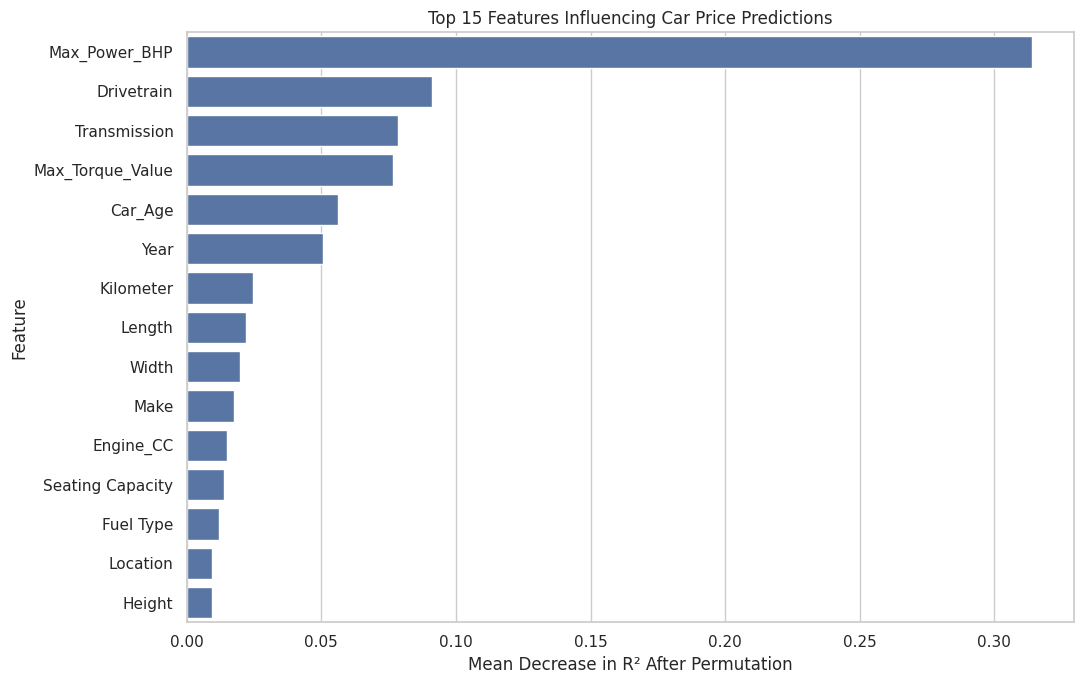

In [25]:

# OASIS INFOBYTE
# Stage 8: Feature Importance Analysis

from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Use the original Extra Trees model
best_model = trained_models["Extra Trees"]

# Calculate permutation importance
importance_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="r2",
    n_jobs=-1
)

# Create importance dataframe
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_result.importances_mean,
    "Std": importance_result.importances_std
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("FEATURE IMPORTANCE RANKING")
display(importance_df.round(4))

# Plot top 15 features
plt.figure(figsize=(11, 7))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features Influencing Car Price Predictions")
plt.xlabel("Mean Decrease in R² After Permutation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [26]:

# OASIS INFOBYTE
# Stage 9: Save Final Model

import joblib

joblib.dump(
    best_model,
    "car_price_prediction_model.pkl"
)

print("Final model saved successfully!")
print("Model: Original Extra Trees Regressor")


Final model saved successfully!
Model: Original Extra Trees Regressor


Feature Importance Ranking:


,Feature,Importance,Std
17,Max_Power_BHP,0.3139,0.0148
10,Drivetrain,0.0911,0.0449
5,Transmission,0.0785,0.0138
18,Max_Torque_Value,0.0765,0.0129
19,Car_Age,0.0561,0.0097
2,Year,0.0505,0.0081
3,Kilometer,0.0245,0.0134
11,Length,0.0219,0.0022
12,Width,0.0197,0.0046
0,Make,0.0175,0.0030


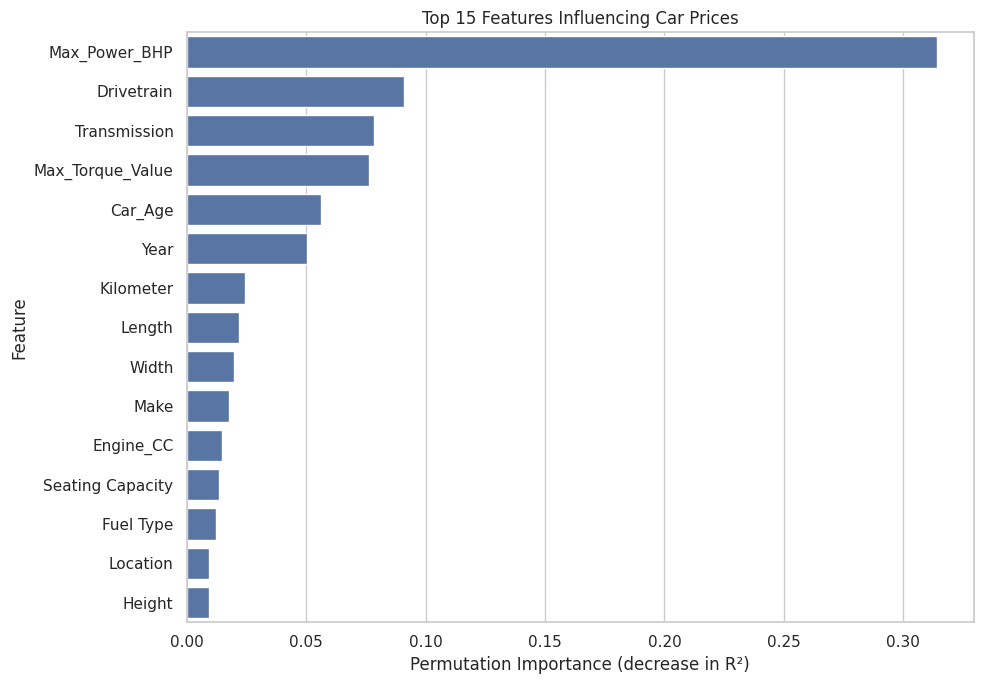

In [27]:

# OASIS INFOBYTE
# Stage 10A: Feature Importance

from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

best_model = trained_models["Extra Trees"]

importance_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="r2",
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_result.importances_mean,
    "Std": importance_result.importances_std
}).sort_values("Importance", ascending=False)

print("Feature Importance Ranking:")
display(importance_df.round(4))

plt.figure(figsize=(10, 7))
sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)
plt.title("Top 15 Features Influencing Car Prices")
plt.xlabel("Permutation Importance (decrease in R²)")
plt.tight_layout()
plt.show()


In [28]:

# OASIS INFOBYTE
# Stage 10B: Load and Test Saved Model

import joblib

loaded_model = joblib.load("car_price_prediction_model.pkl")

# Predict prices for five test records
sample_predictions = loaded_model.predict(X_test.iloc[:5])

verification = pd.DataFrame({
    "Actual Price": y_test.iloc[:5].values,
    "Predicted Price": sample_predictions
})

print("Saved model loaded successfully!")
print("\nSample prediction verification:")
display(verification.round(2))


Saved model loaded successfully!

Sample prediction verification:


,Actual Price,Predicted Price
0,4800000,5012019.98
1,825000,788914.78
2,695000,567875.26
3,950000,1081352.75
4,819999,795837.46


FEATURE IMPORTANCE RANKING


,Feature,Importance,Std
17,Max_Power_BHP,0.3139,0.0148
10,Drivetrain,0.0911,0.0449
5,Transmission,0.0785,0.0138
18,Max_Torque_Value,0.0765,0.0129
19,Car_Age,0.0561,0.0097
2,Year,0.0505,0.0081
3,Kilometer,0.0245,0.0134
11,Length,0.0219,0.0022
12,Width,0.0197,0.0046
0,Make,0.0175,0.0030


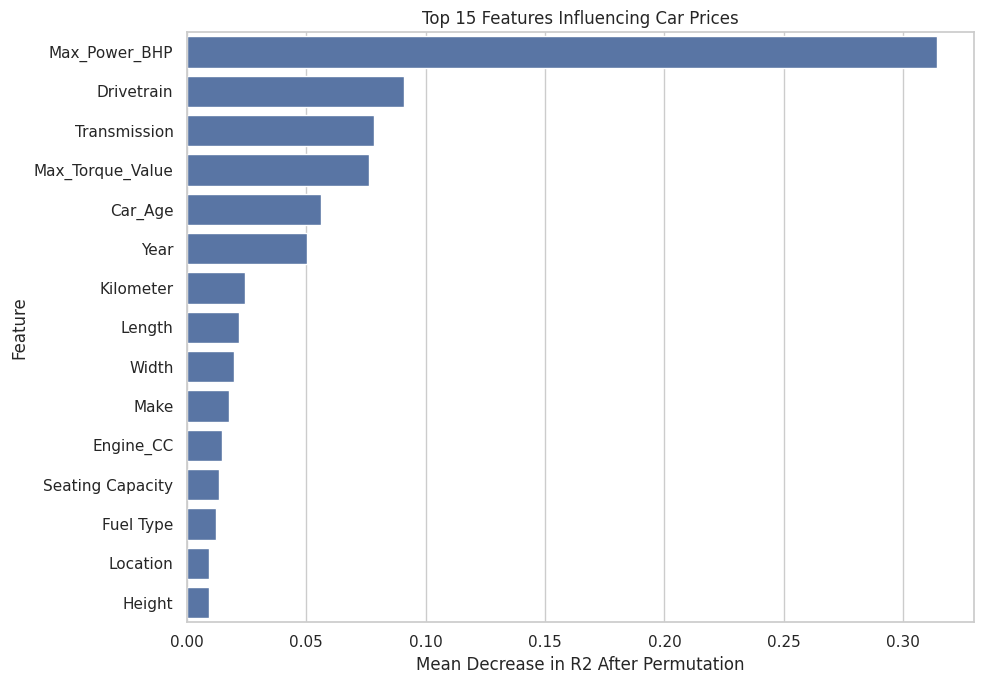

In [29]:

# OASIS INFOBYTE
# Stage 11: Feature Importance Analysis

from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

best_model = trained_models["Extra Trees"]

importance_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="r2",
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_result.importances_mean,
    "Std": importance_result.importances_std
}).sort_values("Importance", ascending=False)

print("FEATURE IMPORTANCE RANKING")
display(importance_df.round(4))

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features Influencing Car Prices")
plt.xlabel("Mean Decrease in R2 After Permutation")
plt.tight_layout()
plt.show()


In [30]:

# Stage 12: Save Project Outputs

import joblib

# Save model
joblib.dump(
    trained_models["Extra Trees"],
    "car_price_prediction_model.pkl"
)

# Save feature importance
importance_df.to_csv(
    "feature_importance.csv",
    index=False
)

# Save prediction results
prediction_results.to_csv(
    "car_price_predictions.csv",
    index=False
)

print("All project outputs saved successfully!")


All project outputs saved successfully!


In [31]:

# Stage 12: Save Project Outputs

import joblib

# Save model
joblib.dump(
    trained_models["Extra Trees"],
    "car_price_prediction_model.pkl"
)

# Save feature importance
importance_df.to_csv(
    "feature_importance.csv",
    index=False
)

# Save prediction results
prediction_results.to_csv(
    "car_price_predictions.csv",
    index=False
)

print("All project outputs saved successfully!")


All project outputs saved successfully!


In [32]:

from google.colab import files

files.download("car_price_prediction_model.pkl")
files.download("feature_importance.csv")
files.download("car_price_predictions.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,Feature,Importance,Std
17,Max_Power_BHP,0.3139,0.0148
10,Drivetrain,0.0911,0.0449
5,Transmission,0.0785,0.0138
18,Max_Torque_Value,0.0765,0.0129
19,Car_Age,0.0561,0.0097
2,Year,0.0505,0.0081
3,Kilometer,0.0245,0.0134
11,Length,0.0219,0.0022
12,Width,0.0197,0.0046
0,Make,0.0175,0.0030


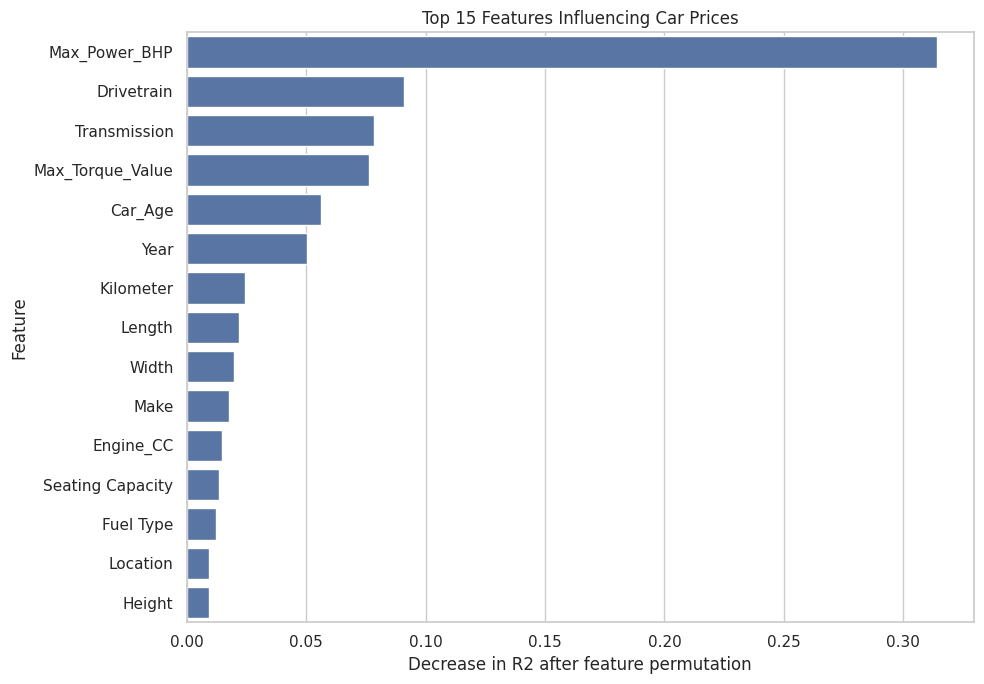

In [33]:

# OASIS INFOBYTE
# Stage 11: Feature Importance

from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

best_model = trained_models["Extra Trees"]

importance_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="r2",
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_result.importances_mean,
    "Std": importance_result.importances_std
}).sort_values("Importance", ascending=False)

display(importance_df.round(4))

plt.figure(figsize=(10, 7))
sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)
plt.title("Top 15 Features Influencing Car Prices")
plt.xlabel("Decrease in R2 after feature permutation")
plt.tight_layout()
plt.show()


In [34]:

# Stage 12: Save Project Outputs

import joblib

joblib.dump(
    trained_models["Extra Trees"],
    "car_price_prediction_model.pkl"
)

importance_df.to_csv("feature_importance.csv", index=False)
prediction_results.to_csv("car_price_predictions.csv", index=False)

print("All project outputs saved successfully!")


All project outputs saved successfully!
